> **Versi 1 (Lexicon)
> Output tabel yang memuat nama pengguna dan foto profil Google Play dihapus dari salinan ini.
> Akurasi 88% di notebook ini diukur terhadap label lexicon, bukan label manusia. Lihat `README.md` untuk evaluasi ulang terhadap gold set.


# **Sentimen Analisis Review APK Play Store - MyTelkomsel**


# **Import Library**

In [ ]:
# Install necessary libraries
!pip install google-play-scraper
!pip install textblob
!pip install sastrawi
!pip install gensim
!pip install xgboost

# =========================
# BASIC LIBRARIES
# =========================
import pandas as pd
import numpy as np
import re
import warnings
import string
import pickle
import json
import time
import datetime as dt
import pickle
import os

# =========================
# WEB SCRAPING
# =========================
from google_play_scraper import app, reviews, Sort

# =========================
# NLP & TEXT PROCESSING
# =========================
import nltk
from nltk.corpus import stopwords

from textblob import TextBlob

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# =========================
# FEATURE EXTRACTION
# =========================
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec

# =========================
# MACHINE LEARNING
# =========================
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, chi2

# Models
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import (
    RandomForestClassifier,
    VotingClassifier
)

from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV

# XGBoost (dinonaktifkan: tidak dipakai di notebook ini, dan di macOS butuh libomp sehingga import gagal)
# from xgboost import XGBClassifier

# =========================
# VISUALIZATION
# =========================
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

# =========================
# CONFIGURATION
# =========================
warnings.filterwarnings('ignore')

# Download NLTK data
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True) # Re-added missing download

# Random seed
seed = 42
np.random.seed(seed)

pd.options.mode.chained_assignment = None

print("✓ Semua library berhasil diimport")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 63.8 MB/s eta 0:00:00
✓ Semua library berhasil diimport


# Scapping Dataset

Pada proyek ini, kita akan melakukan analisis sentimen terhadap ulasan dan pendapat pengguna terkait aplikasi "MyTSEL" di Play Store. Analisis sentimen akan membantu kita untuk memahami bagaimana pengguna merasakan dan mengungkapkan pandangan mereka terhadap aplikasi ini.

Dengan menggunakan berbagai teknik pemrosesan teks dan algoritma machine learning, kita akan mencoba mengidentifikasi apakah ulasan pengguna terhadap aplikasi "MyTSEL" cenderung positif, negatif, atau netral. Hasil analisis sentimen ini dapat memberikan wawasan berharga kepada pengembang aplikasi untuk meningkatkan pengalaman pengguna. Mari kita mulai menjelajahi ulasan pengguna dan menganalisis sentimen di sekitar aplikasi "MyTSEL" dengan lebih mendalam.

In [2]:
# Mengambil semua ulasan dari aplikasi dengan ID 'com.byu.id' di Google Play Store.
# Proses scraping mungkin memerlukan beberapa saat tergantung pada jumlah ulasan yang ada.
# Menggunakan fungsi 'reviews' (singular) untuk membatasi jumlah ulasan berdasarkan parameter 'count'.
scrapreview, _ = reviews(
    'com.telkomsel.telkomselcm',  # ID aplikasi
    lang='id',             # Bahasa ulasan (default: 'en')
    country='id',          # Negara (default: 'us')
    sort=Sort.MOST_RELEVANT, # Urutan ulasan (default: Sort.MOST_RELEVANT)
    count=12000            # Jumlah maksimum ulasan yang ingin diambil (diubah dari 15000 menjadi 12000)
)

# Loading Dataset

In [3]:
app_reviews_df = pd.DataFrame(scrapreview)
app_reviews_df.shape
app_reviews_df.head()
app_reviews_df.to_csv('ulasan_aplikasi_mytsel.csv', index=False)

In [4]:
# Membuat DataFrame dari hasil scrapreview
app_reviews_df = pd.DataFrame(scrapreview)

# Menghitung jumlah baris dan kolom dalam DataFrame
jumlah_ulasan, jumlah_kolom = app_reviews_df.shape


In [5]:
# Menampilkan lima baris pertama dari DataFrame app_reviews_df
app_reviews_df.head()

In [6]:
# Menampilkan informasi tentang DataFrame app_reviews_df
app_reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   reviewId              12000 non-null  object        
 1   userName              12000 non-null  object        
 2   userImage             12000 non-null  object        
 3   content               12000 non-null  object        
 4   score                 12000 non-null  int64         
 5   thumbsUpCount         12000 non-null  int64         
 6   reviewCreatedVersion  11351 non-null  object        
 7   at                    12000 non-null  datetime64[ns]
 8   replyContent          10597 non-null  object        
 9   repliedAt             10597 non-null  datetime64[ns]
 10  appVersion            11351 non-null  object        
dtypes: datetime64[ns](2), int64(2), object(7)
memory usage: 1.0+ MB


In [7]:
# Membuat DataFrame baru (clean_df) dengan menghapus baris yang memiliki nilai yang hilang (NaN) dari app_reviews_df
clean_df = app_reviews_df.dropna(subset='content')
clean_df = app_reviews_df.dropna(subset='score')

In [8]:
# Menampilkan informasi tentang DataFrame clean_df setelah membersihkan nilai yang hilang (NaN)
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   reviewId              12000 non-null  object        
 1   userName              12000 non-null  object        
 2   userImage             12000 non-null  object        
 3   content               12000 non-null  object        
 4   score                 12000 non-null  int64         
 5   thumbsUpCount         12000 non-null  int64         
 6   reviewCreatedVersion  11351 non-null  object        
 7   at                    12000 non-null  datetime64[ns]
 8   replyContent          10597 non-null  object        
 9   repliedAt             10597 non-null  datetime64[ns]
 10  appVersion            11351 non-null  object        
dtypes: datetime64[ns](2), int64(2), object(7)
memory usage: 1.0+ MB


In [9]:
# Menghapus baris duplikat dari DataFrame clean_df
clean_df = clean_df.drop_duplicates()

# Menghitung jumlah baris dan kolom dalam DataFrame clean_df setelah menghapus duplikat
jumlah_ulasan_setelah_hapus_duplikat, jumlah_kolom_setelah_hapus_duplikat = clean_df.shape

print(f"Jumlah ulasan sebelum penghapusan duplikat: {jumlah_ulasan}")
print(f"Jumlah ulasan setelah penghapusan duplikat: {jumlah_ulasan_setelah_hapus_duplikat}")

Jumlah ulasan sebelum penghapusan duplikat: 12000
Jumlah ulasan setelah penghapusan duplikat: 12000


##Preprocessing

Berikut adalah beberapa fungsi yang digunakan untuk membersihkan dan memproses teks. Inilah penjelasan singkat tentang masing-masing fungsi:

1. `cleaningText(text)`: Fungsi ini digunakan untuk membersihkan teks dengan beberapa langkah, seperti menghapus mention, hashtag, RT (retweet), tautan (link), angka, dan tanda baca. Selain itu, itu juga menggantikan karakter newline dengan spasi dan menghilangkan spasi ekstra di awal dan akhir teks.

2. `casefoldingText(text)`: Fungsi ini mengonversi semua karakter dalam teks menjadi huruf kecil (lowercase), sehingga teks menjadi lebih seragam.

3. `tokenizingText(text)`: Fungsi ini digunakan untuk membagi teks menjadi daftar kata atau token. Ini berguna untuk mengurai teks menjadi komponen-komponen dasar.

4. `filteringText(text)`: Fungsi ini digunakan untuk menghapus kata-kata berhenti (stopwords) dalam teks. Anda telah memperbarui daftar kata-kata berhenti dengan beberapa kata tambahan.

5. `stemmingText(text)`: Fungsi ini menerapkan stemming pada teks, yaitu mengurangi kata-kata menjadi bentuk dasarnya. Anda menggunakan pustaka Sastrawi untuk melakukan stemming dalam bahasa Indonesia.

6. `toSentence(list_words)`: Fungsi ini digunakan untuk menggabungkan daftar kata-kata menjadi sebuah kalimat.

Anda dapat menggunakan fungsi-fungsi ini dalam proyek Anda untuk membersihkan, memproses, dan mempersiapkan teks sebelum melakukan analisis sentimen. Pastikan untuk memanggil fungsi-fungsi ini dengan benar sesuai dengan tahap pemrosesan teks yang Anda inginkan.

In [10]:
def cleaningText(text):
    text = re.sub(r'@[A-Za-z0-9]+', '', text) # remove mentions
    text = re.sub(r'#[A-Za-z0-9]+', '', text) # remove hashtag
    text = re.sub(r'RT[\s]', '', text) # remove RT
    text = re.sub(r"http\S+", '', text) # remove link
    text = re.sub(r'[0-9]+', '', text) # remove numbers
    text = re.sub(r'[^\w\s]', '', text) # remove numbers


    text = text.replace('\n', ' ') # replace new line into space
    text = text.translate(str.maketrans('', '', string.punctuation)) # remove all punctuations
    text = text.strip(' ') # remove characters space from both left and right text
    return text

def casefoldingText(text): # Converting all the characters in a text into lower case
    text = text.lower()
    return text

def tokenizingText(text): # Tokenizing or splitting a string, text into a list of tokens
    text = word_tokenize(text)
    return text

def filteringText(text): # Remove stopwors in a text
    listStopwords = set(stopwords.words('indonesian'))
    listStopwords1 = set(stopwords.words('english'))
    listStopwords.update(listStopwords1)
    listStopwords.update(['iya','yaa','gak','nya','na','sih','ku',"di","ga","ya","gaa","loh","kah","woi","woii","woy"])
    filtered = []
    for txt in text:
        if txt not in listStopwords:
            filtered.append(txt)
    text = filtered
    return text

def stemmingText(text): # Reducing a word to its word stem that affixes to suffixes and prefixes or to the roots of words
    # Membuat objek stemmer
    factory = StemmerFactory()
    stemmer = factory.create_stemmer()

    # Memecah teks menjadi daftar kata
    words = text.split()

    # Menerapkan stemming pada setiap kata dalam daftar
    stemmed_words = [stemmer.stem(word) for word in words]

    # Menggabungkan kata-kata yang telah distem
    stemmed_text = ' '.join(stemmed_words)

    return stemmed_text

    return stemmed_text
def toSentence(list_words): # Convert list of words into sentence
    sentence = ' '.join(word for word in list_words)
    return sentence

In [11]:
slangwords = {"@": "di", "abis": "habis", "wtb": "beli", "masi": "masih", "wts": "jual", "wtt": "tukar", "bgt": "banget", "maks": "maksimal", "plisss": "tolong", "bgttt": "banget", "indo": "indonesia", "bgtt": "banget", "ad": "ada", "rv": "redvelvet", "plis": "tolong", "pls": "tolong", "cr": "sumber", "cod": "bayar ditempat", "adlh": "adalah", "afaik": "as far as i know", "ahaha": "haha", "aj": "saja", "ajep-ajep": "dunia gemerlap", "ak": "saya", "akika": "aku", "akkoh": "aku", "akuwh": "aku", "alay": "norak", "alow": "halo", "ambilin": "ambilkan", "ancur": "hancur", "anjrit": "anjing", "anter": "antar", "ap2": "apa-apa", "apasih": "apa sih", "apes": "sial", "aps": "apa", "aq": "saya", "aquwh": "aku", "asbun": "asal bunyi", "aseekk": "asyik", "asekk": "asyik", "asem": "asam", "aspal": "asli tetapi palsu", "astul": "asal tulis", "ato": "atau", "au ah": "tidak mau tahu", "awak": "saya", "ay": "sayang", "ayank": "sayang", "b4": "sebelum", "bakalan": "akan", "bandes": "bantuan desa", "bangedh": "banget", "banpol": "bantuan polisi", "banpur": "bantuan tempur", "basbang": "basi", "bcanda": "bercanda", "bdg": "bandung", "begajulan": "nakal", "beliin": "belikan", "bencong": "banci", "bentar": "sebentar", "ber3": "bertiga", "beresin": "membereskan", "bete": "bosan", "beud": "banget", "bg": "abang", "bgmn": "bagaimana", "bgt": "banget", "bijimane": "bagaimana", "bintal": "bimbingan mental", "bkl": "akan", "bknnya": "bukannya", "blegug": "bodoh", "blh": "boleh", "bln": "bulan", "blum": "belum", "bnci": "benci", "bnran": "yang benar", "bodor": "lucu", "bokap": "ayah", "boker": "buang air besar", "bokis": "bohong", "boljug": "boleh juga", "bonek": "bocah nekat", "boyeh": "boleh", "br": "baru", "brg": "bareng", "bro": "saudara laki-laki", "bru": "baru", "bs": "bisa", "bsen": "bosan", "bt": "buat", "btw": "ngomong-ngomong", "buaya": "tidak setia", "bubbu": "tidur", "bubu": "tidur", "bumil": "ibu hamil", "bw": "bawa", "bwt": "buat", "byk": "banyak", "byrin": "bayarkan", "cabal": "sabar", "cadas": "keren", "calo": "makelar", "can": "belum", "capcus": "pergi", "caper": "cari perhatian", "ce": "cewek", "cekal": "cegah tangkal", "cemen": "penakut", "cengengesan": "tertawa", "cepet": "cepat", "cew": "cewek", "chuyunk": "sayang", "cimeng": "ganja", "cipika cipiki": "cium pipi kanan cium pipi kiri", "ciyh": "sih", "ckepp": "cakep", "ckp": "cakep", "cmiiw": "correct me if i'm wrong", "cmpur": "campur", "cong": "banci", "conlok": "cinta lokasi", "cowwyy": "maaf", "cp": "siapa", "cpe": "capek", "cppe": "capek", "cucok": "cocok", "cuex": "cuek", "cumi": "Cuma miscall", "cups": "culun", "curanmor": "pencurian kendaraan bermotor", "curcol": "curahan hati colongan", "cwek": "cewek", "cyin": "cinta", "d": "di", "dah": "deh", "dapet": "dapat", "de": "adik", "dek": "adik", "demen": "suka", "deyh": "deh", "dgn": "dengan", "diancurin": "dihancurkan", "dimaafin": "dimaafkan", "dimintak": "diminta", "disono": "di sana", "dket": "dekat", "dkk": "dan kawan-kawan", "dll": "dan lain-lain", "dlu": "dulu", "dngn": "dengan", "dodol": "bodoh", "doku": "uang", "dongs": "dong", "dpt": "dapat", "dri": "dari", "drmn": "darimana", "drtd": "dari tadi", "dst": "dan seterusnya", "dtg": "datang", "duh": "aduh", "duren": "durian", "ed": "edisi", "egp": "emang gue pikirin", "eke": "aku", "elu": "kamu", "emangnya": "memangnya", "emng": "memang", "endak": "tidak", "enggak": "tidak", "envy": "iri", "ex": "mantan", "fax": "facsimile", "fifo": "first in first out", "folbek": "follow back", "fyi": "sebagai informasi", "gaada": "tidak ada uang", "gag": "tidak", "gaje": "tidak jelas", "gak papa": "tidak apa-apa", "gan": "juragan", "gaptek": "gagap teknologi", "gatek": "gagap teknologi", "gawe": "kerja", "gbs": "tidak bisa", "gebetan": "orang yang disuka", "geje": "tidak jelas", "gepeng": "gelandangan dan pengemis", "ghiy": "lagi", "gile": "gila", "gimana": "bagaimana", "gino": "gigi nongol", "githu": "gitu", "gj": "tidak jelas", "gmana": "bagaimana", "gn": "begini", "goblok": "bodoh", "golput": "golongan putih", "gowes": "mengayuh sepeda", "gpny": "tidak punya", "gr": "gede rasa", "gretongan": "gratisan", "gtau": "tidak tahu", "gua": "saya", "guoblok": "goblok", "gw": "saya", "ha": "tertawa", "haha": "tertawa", "hallow": "halo", "hankam": "pertahanan dan keamanan", "hehe": "he", "helo": "halo", "hey": "hai", "hlm": "halaman", "hny": "hanya", "hoax": "isu bohong", "hr": "hari", "hrus": "harus", "hubdar": "perhubungan darat", "huff": "mengeluh", "hum": "rumah", "humz": "rumah", "ilang": "hilang", "ilfil": "tidak suka", "imho": "in my humble opinion", "imoetz": "imut", "item": "hitam", "itungan": "hitungan", "iye": "iya", "ja": "saja", "jadiin": "jadi", "jaim": "jaga image", "jayus": "tidak lucu", "jdi": "jadi", "jem": "jam", "jga": "juga", "jgnkan": "jangankan", "jir": "anjing", "jln": "jalan", "jomblo": "tidak punya pacar", "jubir": "juru bicara", "jutek": "galak", "k": "ke", "kab": "kabupaten", "kabor": "kabur", "kacrut": "kacau", "kadiv": "kepala divisi", "kagak": "tidak", "kalo": "kalau", "kampret": "sialan", "kamtibmas": "keamanan dan ketertiban masyarakat", "kamuwh": "kamu", "kanwil": "kantor wilayah", "karna": "karena", "kasubbag": "kepala subbagian", "katrok": "kampungan", "kayanya": "kayaknya", "kbr": "kabar", "kdu": "harus", "kec": "kecamatan", "kejurnas": "kejuaraan nasional", "kekeuh": "keras kepala", "kel": "kelurahan", "kemaren": "kemarin", "kepengen": "mau", "kepingin": "mau", "kepsek": "kepala sekolah", "kesbang": "kesatuan bangsa", "kesra": "kesejahteraan rakyat", "ketrima": "diterima", "kgiatan": "kegiatan", "kibul": "bohong", "kimpoi": "kawin", "kl": "kalau", "klianz": "kalian", "kloter": "kelompok terbang", "klw": "kalau", "km": "kamu", "kmps": "kampus", "kmrn": "kemarin", "knal": "kenal", "knp": "kenapa", "kodya": "kota madya", "komdis": "komisi disiplin", "komsov": "komunis sovyet", "kongkow": "kumpul bareng teman-teman", "kopdar": "kopi darat", "korup": "korupsi", "kpn": "kapan", "krenz": "keren", "krm": "kirim", "kt": "kita", "ktmu": "ketemu", "ktr": "kantor", "kuper": "kurang pergaulan", "kw": "imitasi", "kyk": "seperti", "la": "lah", "lam": "salam", "lamp": "lampiran", "lanud": "landasan udara", "latgab": "latihan gabungan", "lebay": "berlebihan", "leh": "boleh", "lelet": "lambat", "lemot": "lambat", "lgi": "lagi", "lgsg": "langsung", "liat": "lihat", "litbang": "penelitian dan pengembangan", "lmyn": "lumayan", "lo": "kamu", "loe": "kamu", "lola": "lambat berfikir", "louph": "cinta", "low": "kalau", "lp": "lupa", "luber": "langsung, umum, bebas, dan rahasia", "luchuw": "lucu", "lum": "belum", "luthu": "lucu", "lwn": "lawan", "maacih": "terima kasih", "mabal": "bolos", "macem": "macam", "macih": "masih", "maem": "makan", "magabut": "makan gaji buta", "maho": "homo", "mak jang": "kaget", "maksain": "memaksa", "malem": "malam", "mam": "makan", "maneh": "kamu", "maniez": "manis", "mao": "mau", "masukin": "masukkan", "melu": "ikut", "mepet": "dekat sekali", "mgu": "minggu", "migas": "minyak dan gas bumi", "mikol": "minuman beralkohol", "miras": "minuman keras", "mlah": "malah", "mngkn": "mungkin", "mo": "mau", "mokad": "mati", "moso": "masa", "mpe": "sampai", "msk": "masuk", "mslh": "masalah", "mt": "makan teman", "mubes": "musyawarah besar", "mulu": "melulu", "mumpung": "selagi", "munas": "musyawarah nasional", "muntaber": "muntah dan berak", "musti": "mesti", "muupz": "maaf", "mw": "now watching", "n": "dan", "nanam": "menanam", "nanya": "bertanya", "napa": "kenapa", "napi": "narapidana", "napza": "narkotika, alkohol, psikotropika, dan zat adiktif ", "narkoba": "narkotika, psikotropika, dan obat terlarang", "nasgor": "nasi goreng", "nda": "tidak", "ndiri": "sendiri", "ne": "ini", "nekolin": "neokolonialisme", "nembak": "menyatakan cinta", "ngabuburit": "menunggu berbuka puasa", "ngaku": "mengaku", "ngambil": "mengambil", "nganggur": "tidak punya pekerjaan", "ngapah": "kenapa", "ngaret": "terlambat", "ngasih": "memberikan", "ngebandel": "berbuat bandel", "ngegosip": "bergosip", "ngeklaim": "mengklaim", "ngeksis": "menjadi eksis", "ngeles": "berkilah", "ngelidur": "menggigau", "ngerampok": "merampok", "ngga": "tidak", "ngibul": "berbohong", "ngiler": "mau", "ngiri": "iri", "ngisiin": "mengisikan", "ngmng": "bicara", "ngomong": "bicara", "ngubek2": "mencari-cari", "ngurus": "mengurus", "nie": "ini", "nih": "ini", "niyh": "nih", "nmr": "nomor", "nntn": "nonton", "nobar": "nonton bareng", "np": "now playing", "ntar": "nanti", "ntn": "nonton", "numpuk": "bertumpuk", "nutupin": "menutupi", "nyari": "mencari", "nyekar": "menyekar", "nyicil": "mencicil", "nyoblos": "mencoblos", "nyokap": "ibu", "ogah": "tidak mau", "ol": "online", "ongkir": "ongkos kirim", "oot": "out of topic", "org2": "orang-orang", "ortu": "orang tua", "otda": "otonomi daerah", "otw": "on the way, sedang di jalan", "pacal": "pacar", "pake": "pakai", "pala": "kepala", "pansus": "panitia khusus", "parpol": "partai politik", "pasutri": "pasangan suami istri", "pd": "pada", "pede": "percaya diri", "pelatnas": "pemusatan latihan nasional", "pemda": "pemerintah daerah", "pemkot": "pemerintah kota", "pemred": "pemimpin redaksi", "penjas": "pendidikan jasmani", "perda": "peraturan daerah", "perhatiin": "perhatikan", "pesenan": "pesanan", "pgang": "pegang", "pi": "tapi", "pilkada": "pemilihan kepala daerah", "pisan": "sangat", "pk": "penjahat kelamin", "plg": "paling", "pmrnth": "pemerintah", "polantas": "polisi lalu lintas", "ponpes": "pondok pesantren", "pp": "pulang pergi", "prg": "pergi", "prnh": "pernah", "psen": "pesan", "pst": "pasti", "pswt": "pesawat", "pw": "posisi nyaman", "qmu": "kamu", "rakor": "rapat koordinasi", "ranmor": "kendaraan bermotor", "re": "reply", "ref": "referensi", "rehab": "rehabilitasi", "rempong": "sulit", "repp": "balas", "restik": "reserse narkotika", "rhs": "rahasia", "rmh": "rumah", "ru": "baru", "ruko": "rumah toko", "rusunawa": "rumah susun sewa", "ruz": "terus", "saia": "saya", "salting": "salah tingkah", "sampe": "sampai", "samsek": "sama sekali", "sapose": "siapa", "satpam": "satuan pengamanan", "sbb": "sebagai berikut", "sbh": "sebuah", "sbnrny": "sebenarnya", "scr": "secara", "sdgkn": "sedangkan", "sdkt": "sedikit", "se7": "setuju", "sebelas dua belas": "mirip", "sembako": "sembilan bahan pokok", "sempet": "sempat", "sendratari": "seni drama tari", "sgt": "sangat", "shg": "sehingga", "siech": "sih", "sikon": "situasi dan kondisi", "sinetron": "sinema elektronik", "siramin": "siramkan", "sj": "saja", "skalian": "sekalian", "sklh": "sekolah", "skt": "sakit", "slesai": "selesai", "sll": "selalu", "slma": "selama", "slsai": "selesai", "smpt": "sempat", "smw": "semua", "sndiri": "sendiri", "soljum": "sholat jumat", "songong": "sombong", "sory": "maaf", "sosek": "sosial-ekonomi", "sotoy": "sok tahu", "spa": "siapa", "sppa": "siapa", "spt": "seperti", "srtfkt": "sertifikat", "stiap": "setiap", "stlh": "setelah", "suk": "masuk", "sumpek": "sempit", "syg": "sayang", "t4": "tempat", "tajir": "kaya", "tau": "tahu", "taw": "tahu", "td": "tadi", "tdk": "tidak", "teh": "kakak perempuan", "telat": "terlambat", "telmi": "telat berpikir", "temen": "teman", "tengil": "menyebalkan", "tepar": "terkapar", "tggu": "tunggu", "tgu": "tunggu", "thankz": "terima kasih", "thn": "tahun", "tilang": "bukti pelanggaran", "tipiwan": "TvOne", "tks": "terima kasih", "tlp": "telepon", "tls": "tulis", "tmbah": "tambah", "tmen2": "teman-teman", "tmpah": "tumpah", "tmpt": "tempat", "tngu": "tunggu", "tnyta": "ternyata", "tokai": "tai", "toserba": "toko serba ada", "tpi": "tapi", "trdhulu": "terdahulu", "trima": "terima kasih", "trm": "terima", "trs": "terus", "trutama": "terutama", "ts": "penulis", "tst": "tahu sama tahu", "ttg": "tentang", "tuch": "tuh", "tuir": "tua", "tw": "tahu", "u": "kamu", "ud": "sudah", "udah": "sudah", "ujg": "ujung", "ul": "ulangan", "unyu": "lucu", "uplot": "unggah", "urang": "saya", "usah": "perlu", "utk": "untuk", "valas": "valuta asing", "w/": "dengan", "wadir": "wakil direktur", "wamil": "wajib militer", "warkop": "warung kopi", "warteg": "warung tegal", "wat": "buat", "wkt": "waktu", "wtf": "what the fuck", "xixixi": "tertawa", "ya": "iya", "yap": "iya", "yaudah": "ya sudah", "yawdah": "ya sudah", "yg": "yang", "yl": "yang lain", "yo": "iya", "yowes": "ya sudah", "yup": "iya", "7an": "tujuan", "ababil": "abg labil", "acc": "accord", "adlah": "adalah", "adoh": "aduh", "aha": "tertawa", "aing": "saya", "aja": "saja", "ajj": "saja", "aka": "dikenal juga sebagai", "akko": "aku", "akku": "aku", "akyu": "aku", "aljasa": "asal jadi saja", "ama": "sama", "ambl": "ambil", "anjir": "anjing", "ank": "anak", "ap": "apa", "apaan": "apa", "ape": "apa", "aplot": "unggah", "apva": "apa", "aqu": "aku", "asap": "sesegera mungkin", "aseek": "asyik", "asek": "asyik", "aseknya": "asyiknya", "asoy": "asyik", "astrojim": "astagfirullahaladzim", "ath": "kalau begitu", "atuh": "kalau begitu", "ava": "avatar", "aws": "awas", "ayang": "sayang", "ayok": "ayo", "bacot": "banyak bicara", "bales": "balas", "bangdes": "pembangunan desa", "bangkotan": "tua", "banpres": "bantuan presiden", "bansarkas": "bantuan sarana kesehatan", "bazis": "badan amal, zakat, infak, dan sedekah", "bcoz": "karena", "beb": "sayang", "bejibun": "banyak", "belom": "belum", "bener": "benar", "ber2": "berdua", "berdikari": "berdiri di atas kaki sendiri", "bet": "banget", "beti": "beda tipis", "beut": "banget", "bgd": "banget", "bgs": "bagus", "bhubu": "tidur", "bimbuluh": "bimbingan dan penyuluhan", "bisi": "kalau-kalau", "bkn": "bukan", "bl": "beli", "blg": "bilang", "blm": "belum", "bls": "balas", "bnchi": "benci", "bngung": "bingung", "bnyk": "banyak", "bohay": "badan aduhai", "bokep": "porno", "bokin": "pacar", "bole": "boleh", "bolot": "bodoh", "bonyok": "ayah ibu", "bpk": "bapak", "brb": "segera kembali", "brngkt": "berangkat", "brp": "berapa", "brur": "saudara laki-laki", "bsa": "bisa", "bsk": "besok", "bu_bu": "tidur", "bubarin": "bubarkan", "buber": "buka bersama", "bujubune": "luar biasa", "buser": "buru sergap", "bwhn": "bawahan", "byar": "bayar", "byr": "bayar", "c8": "chat", "cabut": "pergi", "caem": "cakep", "cama-cama": "sama-sama", "cangcut": "celana dalam", "cape": "capek", "caur": "jelek", "cekak": "tidak ada uang", "cekidot": "coba lihat", "cemplungin": "cemplungkan", "ceper": "pendek", "ceu": "kakak perempuan", "cewe": "cewek", "cibuk": "sibuk", "cin": "cinta", "ciye": "cie", "ckck": "ck", "clbk": "cinta lama bersemi kembali", "cmpr": "campur", "cnenk": "senang", "congor": "mulut", "cow": "cowok", "coz": "karena", "cpa": "siapa", "gokil": "gila", "gombal": "suka merayu", "gpl": "tidak pakai lama", "gpp": "tidak apa-apa", "gretong": "gratis", "gt": "begitu", "gtw": "tidak tahu", "gue": "saya", "guys": "teman-teman", "gws": "cepat sembuh", "haghaghag": "tertawa", "hakhak": "tertawa", "handak": "bahan peledak", "hansip": "pertahanan sipil", "hellow": "halo", "helow": "halo", "hi": "hai", "hlng": "hilang", "hnya": "hanya", "houm": "rumah", "hrs": "harus", "hubad": "hubungan angkatan darat", "hubla": "perhubungan laut", "huft": "mengeluh", "humas": "hubungan masyarakat", "idk": "saya tidak tahu", "ilfeel": "tidak suka", "imba": "jago sekali", "imoet": "imut", "info": "informasi", "itung": "hitung", "isengin": "bercanda", "iyala": "iya lah", "iyo": "iya", "jablay": "jarang dibelai", "jadul": "jaman dulu", "jancuk": "anjing", "jd": "jadi", "jdikan": "jadikan", "jg": "juga", "jgn": "jangan", "jijay": "jijik", "jkt": "jakarta", "jnj": "janji", "jth": "jatuh", "jurdil": "jujur adil", "jwb": "jawab", "ka": "kakak", "kabag": "kepala bagian", "kacian": "kasihan", "kadit": "kepala direktorat", "kaga": "tidak", "kaka": "kakak", "kamtib": "keamanan dan ketertiban", "kamuh": "kamu", "kamyu": "kamu", "kapt": "kapten", "kasat": "kepala satuan", "kasubbid": "kepala subbidang", "kau": "kamu", "kbar": "kabar", "kcian": "kasihan", "keburu": "terlanjur", "kedubes": "kedutaan besar", "kek": "seperti", "keknya": "kayaknya", "keliatan": "kelihatan", "keneh": "masih", "kepikiran": "terpikirkan", "kepo": "mau tahu urusan orang", "kere": "tidak punya uang", "kesian": "kasihan", "ketauan": "ketahuan", "keukeuh": "keras kepala", "khan": "kan", "kibus": "kaki busuk", "kk": "kakak", "klian": "kalian", "klo": "kalau", "kluarga": "keluarga", "klwrga": "keluarga", "kmari": "kemari", "kmpus": "kampus", "kn": "kan", "knl": "kenal", "knpa": "kenapa", "kog": "kok", "kompi": "komputer", "komtiong": "komunis Tiongkok", "konjen": "konsulat jenderal", "koq": "kok", "kpd": "kepada", "kptsan": "keputusan", "krik": "garing", "krn": "karena", "ktauan": "ketahuan", "ktny": "katanya", "kudu": "harus", "kuq": "kok", "ky": "seperti", "kykny": "kayanya", "laka": "kecelakaan", "lambreta": "lambat", "lansia": "lanjut usia", "lapas": "lembaga pemasyarakatan", "lbur": "libur", "lekong": "laki-laki", "lg": "lagi", "lgkp": "lengkap", "lht": "lihat", "linmas": "perlindungan masyarakat", "lmyan": "lumayan", "lngkp": "lengkap", "loch": "loh", "lol": "tertawa", "lom": "belum", "loupz": "cinta", "lowh": "kamu", "lu": "kamu", "luchu": "lucu", "luff": "cinta", "luph": "cinta", "lw": "kamu", "lwt": "lewat", "maaciw": "terima kasih", "mabes": "markas besar", "macem-macem": "macam-macam", "madesu": "masa depan suram", "maen": "main", "mahatma": "maju sehat bersama", "mak": "ibu", "makasih": "terima kasih", "malah": "bahkan", "malu2in": "memalukan", "mamz": "makan", "manies": "manis", "mantep": "mantap", "markus": "makelar kasus", "mba": "mbak", "mending": "lebih baik", "mgkn": "mungkin", "mhn": "mohon", "miker": "minuman keras", "milis": "mailing list", "mksd": "maksud", "mls": "malas", "mnt": "minta", "moge": "motor gede", "mokat": "mati", "mosok": "masa", "msh": "masih", "mskpn": "meskipun", "msng2": "masing-masing", "muahal": "mahal", "muker": "musyawarah kerja", "mumet": "pusing", "muna": "munafik", "munaslub": "musyawarah nasional luar biasa", "musda": "musyawarah daerah", "muup": "maaf", "muuv": "maaf", "nal": "kenal", "nangis": "menangis", "naon": "apa", "napol": "narapidana politik", "naq": "anak", "narsis": "bangga pada diri sendiri", "nax": "anak", "ndak": "tidak", "ndut": "gendut", "nekolim": "neokolonialisme", "nelfon": "menelepon", "ngabis2in": "menghabiskan", "ngakak": "tertawa", "ngambek": "marah", "ngampus": "pergi ke kampus", "ngantri": "mengantri", "ngapain": "sedang apa", "ngaruh": "berpengaruh", "ngawur": "berbicara sembarangan", "ngeceng": "kumpul bareng-bareng", "ngeh": "sadar", "ngekos": "tinggal di kos", "ngelamar": "melamar", "ngeliat": "melihat", "ngemeng": "bicara terus-terusan", "ngerti": "mengerti", "nggak": "tidak", "ngikut": "ikut", "nginep": "menginap", "ngisi": "mengisi", "ngmg": "bicara", "ngocol": "lucu", "ngomongin": "membicarakan", "ngumpul": "berkumpul", "ni": "ini", "nyasar": "tersesat", "nyariin": "mencari", "nyiapin": "mempersiapkan", "nyiram": "menyiram", "nyok": "ayo", "o/": "oleh", "ok": "ok", "priksa": "periksa", "pro": "profesional", "psn": "pesan", "psti": "pasti", "puanas": "panas", "qmo": "kamu", "qt": "kita", "rame": "ramai", "raskin": "rakyat miskin", "red": "redaksi", "reg": "register", "rejeki": "rezeki", "renstra": "rencana strategis", "reskrim": "reserse kriminal", "sni": "sini", "somse": "sombong sekali", "sorry": "maaf", "sosbud": "sosial-budaya", "sospol": "sosial-politik", "sowry": "maaf", "spd": "sepeda", "sprti": "seperti", "spy": "supaya", "stelah": "setelah", "subbag": "subbagian", "sumbangin": "sumbangkan", "sy": "saya", "syp": "siapa", "tabanas": "tabungan pembangunan nasional", "tar": "nanti", "taun": "tahun", "tawh": "tahu", "tdi": "tadi", "te2p": "tetap", "tekor": "rugi", "telkom": "telekomunikasi", "telp": "telepon", "temen2": "teman-teman", "tengok": "menjenguk", "terbitin": "terbitkan", "tgl": "tanggal", "thanks": "terima kasih", "thd": "terhadap", "thx": "terima kasih", "tipi": "TV", "tkg": "tukang", "tll": "terlalu", "tlpn": "telepon", "tman": "teman", "tmbh": "tambah", "tmn2": "teman-teman", "tmph": "tumpah", "tnda": "tanda", "tnh": "tanah", "togel": "toto gelap", "tp": "tapi", "tq": "terima kasih", "trgntg": "tergantung", "trims": "terima kasih", "cb": "coba", "y": "ya", "munfik": "munafik", "reklamuk": "reklamasi", "sma": "sama", "tren": "trend", "ngehe": "kesal", "mz": "mas", "analisise": "analisis", "sadaar": "sadar", "sept": "september", "nmenarik": "menarik", "zonk": "bodoh", "rights": "benar", "simiskin": "miskin", "ngumpet": "sembunyi", "hardcore": "keras", "akhirx": "akhirnya", "solve": "solusi", "watuk": "batuk", "ngebully": "intimidasi", "masy": "masyarakat", "still": "masih", "tauk": "tahu", "mbual": "bual", "tioghoa": "tionghoa", "ngentotin": "senggama", "kentot": "senggama", "faktakta": "fakta", "sohib": "teman", "rubahnn": "rubah", "trlalu": "terlalu", "nyela": "cela", "heters": "pembenci", "nyembah": "sembah", "most": "paling", "ikon": "lambang", "light": "terang", "pndukung": "pendukung", "setting": "atur", "seting": "akting", "next": "lanjut", "waspadalah": "waspada", "gantengsaya": "ganteng", "parte": "partai", "nyerang": "serang", "nipu": "tipu", "ktipu": "tipu", "jentelmen": "berani", "buangbuang": "buang", "tsangka": "tersangka", "kurng": "kurang", "ista": "nista", "less": "kurang", "koar": "teriak", "paranoid": "takut", "problem": "masalah", "tahi": "kotoran", "tirani": "tiran", "tilep": "tilap", "happy": "bahagia", "tak": "tidak", "penertiban": "tertib", "uasai": "kuasa", "mnolak": "tolak", "trending": "trend", "taik": "tahi", "wkwkkw": "tertawa", "ahokncc": "ahok", "istaa": "nista", "benarjujur": "jujur", "mgkin": "mungkin"}
def fix_slangwords(text):
    words = text.split()
    fixed_words = []

    for word in words:
        if word.lower() in slangwords:
            fixed_words.append(slangwords[word.lower()])
        else:
            fixed_words.append(word)

    fixed_text = ' '.join(fixed_words)
    return fixed_text

Kamus slang atau daftar kata-kata slang yang Anda berikan adalah kumpulan kata-kata slang bahasa Indonesia beserta terjemahan atau artinya dalam bahasa formal. Fungsi dari kamus slang seperti ini adalah:

1. **Mengartikan Slang:** Kamus slang membantu orang yang mungkin tidak familiar dengan bahasa slang atau ekspresi yang digunakan di kalangan tertentu untuk memahami makna kata-kata tersebut.

2. **Komunikasi Informal:** Slang sering digunakan dalam percakapan informal atau di media sosial. Kamus slang membantu orang untuk berkomunikasi dengan gaya yang lebih santai dan sesuai dengan konteksnya.

3. **Pemahaman Budaya Pop:** Slang sering kali terkait dengan budaya pop dan dapat mencerminkan tren dan perubahan dalam bahasa. Kamus slang memungkinkan orang untuk mengikuti dan memahami bahasa dalam konteks budaya ini.

4. **Penggunaan Sastra dan Penulisan:** Penulis atau pembicara mungkin ingin menggunakan slang dalam tulisannya untuk menciptakan efek tertentu atau mengekspresikan karakter atau setting yang lebih realistis. Kamus slang dapat membantu mereka memilih kata-kata dengan tepat.

5. **Hiburan dan Curiositas:** Beberapa orang mungkin tertarik untuk mempelajari bahasa slang hanya untuk hiburan atau karena rasa ingin tahu terhadap variasi bahasa dan ungkapan dalam bahasa sehari-hari.

Ingatlah bahwa penggunaan slang harus disesuaikan dengan konteks dan audiens. Slang cenderung lebih cocok untuk percakapan santai dengan teman-teman atau di lingkungan yang informal. Dalam situasi formal, penggunaan bahasa formal lebih sesuai.

In [12]:
clean_df

In [13]:
from nltk.tokenize import word_tokenize # Added missing import
import nltk # Ensure nltk is imported for download

# Download the necessary NLTK resource explicitly before use
nltk.download('punkt_tab')

# Membersihkan teks dan menyimpannya di kolom 'text_clean'
clean_df['text_clean'] = clean_df['content'].apply(cleaningText)

# Mengubah huruf dalam teks menjadi huruf kecil dan menyimpannya di 'text_casefoldingText'
clean_df['text_casefoldingText'] = clean_df['text_clean'].apply(casefoldingText)

# Mengganti kata-kata slang dengan kata-kata standar dan menyimpannya di 'text_slangwords'
clean_df['text_slangwords'] = clean_df['text_casefoldingText'].apply(fix_slangwords)

# Memecah teks menjadi token (kata-kata) dan menyimpannya di 'text_tokenizingText'
clean_df['text_tokenizingText'] = clean_df['text_slangwords'].apply(tokenizingText)

# Menghapus kata-kata stop (kata-kata umum) dan menyimpannya di 'text_stopword'
clean_df['text_stopword'] = clean_df['text_tokenizingText'].apply(filteringText)

# Menggabungkan token-token menjadi kalimat dan menyimpannya di 'text_akhir'
clean_df['text_akhir'] = clean_df['text_stopword'].apply(toSentence)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [14]:
clean_df

##Pelabelan Berdasarkan Sentimen

In [15]:
import csv
import requests
from io import StringIO

# Loads positive lexicon data from GitHub
# Membaca data kamus kata-kata positif dari GitHub
lexicon_positive = dict()

response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_positive.csv')
# Mengirim permintaan HTTP untuk mendapatkan file CSV dari GitHub

if response.status_code == 200:
    # Jika permintaan berhasil
    reader = csv.reader(StringIO(response.text), delimiter=',')
    # Membaca teks respons sebagai file CSV menggunakan pembaca CSV dengan pemisah koma

    for row in reader:
        # Mengulangi setiap baris dalam file CSV
        lexicon_positive[row[0]] = int(row[1])
        # Menambahkan kata-kata positif dan skornya ke dalam kamus lexicon_positive
else:
    print("Failed to fetch positive lexicon data")

# Loads negative lexicon data from GitHub
# Membaca data kamus kata-kata negatif dari GitHub
lexicon_negative = dict()

response = requests.get('https://raw.githubusercontent.com/angelmetanosaa/dataset/main/lexicon_negative.csv')
# Mengirim permintaan HTTP untuk mendapatkan file CSV dari GitHub

if response.status_code == 200:
    # Jika permintaan berhasil
    reader = csv.reader(StringIO(response.text), delimiter=',')
    # Membaca teks respons sebagai file CSV menggunakan pembaca CSV dengan pemisah koma

    for row in reader:
        # Mengulangi setiap baris dalam file CSV
        lexicon_negative[row[0]] = int(row[1])
        # Menambahkan kata-kata negatif dan skornya ke dalam kamus lexicon_negative
else:
    print("Failed to fetch negative lexicon data")

In [16]:
# Function to determine sentiment polarity of tweets
# Fungsi untuk menentukan polaritas sentimen dari tweet

def sentiment_analysis_lexicon_indonesia(text):
    #for word in text:

    score = 0
    # Inisialisasi skor sentimen ke 0

    for word in text:
        # Mengulangi setiap kata dalam teks

        if (word in lexicon_positive):
            score = score + lexicon_positive[word]
            # Jika kata ada dalam kamus positif, tambahkan skornya ke skor sentimen

    for word in text:
        # Mengulangi setiap kata dalam teks (sekali lagi)

        if (word in lexicon_negative):
            score = score + lexicon_negative[word]
            # Jika kata ada dalam kamus negatif, kurangkan skornya dari skor sentimen

    polarity=''
    # Inisialisasi variabel polaritas

    if (score >= 0):
        polarity = 'positive'
        # Jika skor sentimen lebih besar atau sama dengan 0, maka polaritas adalah positif
    elif (score < 0):
        polarity = 'negative'
        # Jika skor sentimen kurang dari 0, maka polaritas adalah negatif

    # else:
    #     polarity = 'neutral'
    # Ini adalah bagian yang bisa digunakan untuk menentukan polaritas netral jika diperlukan

    return score, polarity
    # Mengembalikan skor sentimen dan polaritas teks

In [17]:
results = clean_df['text_stopword'].apply(sentiment_analysis_lexicon_indonesia)
results = list(zip(*results))
clean_df['polarity_score'] = results[0]
clean_df['polarity'] = results[1]
print(clean_df['polarity'].value_counts())

polarity
negative    7024
positive    4976
Name: count, dtype: int64


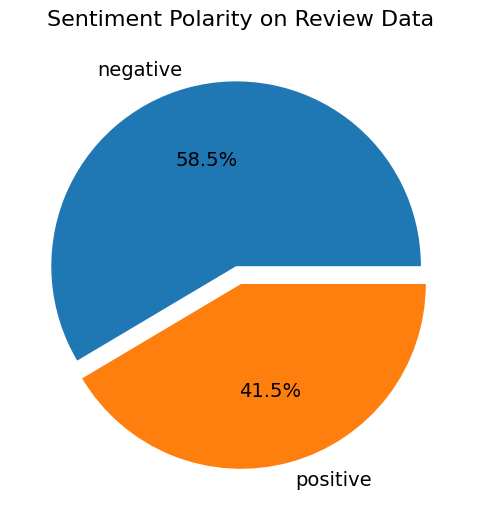

In [18]:
import matplotlib.pyplot as plt

# Membuat objek gambar dan sumbu dengan ukuran (6, 6) inci.
fig, ax = plt.subplots(figsize=(6, 6))

# Mengambil jumlah data polaritas sentimen dari DataFrame 'clean_df' dan menyimpannya dalam list 'sizes'.
sizes = [count for count in clean_df['polarity'].value_counts()]

# Mengambil label atau kategori sentimen dari DataFrame 'clean_df' dan menyimpannya dalam list 'labels'.
labels = list(clean_df['polarity'].value_counts().index)

# Menentukan seberapa jauh potongan dari pie chart akan ditarik (0.1 artinya potongan pertama akan sedikit terpisah).
explode = (0.1, 0)

# Membuat pie chart dengan data 'sizes', 'labels', dan 'explode' yang telah ditentukan.
# Autopct digunakan untuk menampilkan persentase di dalam setiap potongan pie.
# Textprops digunakan untuk mengatur ukuran font teks dalam pie chart.
ax.pie(x=sizes, labels=labels, autopct='%1.1f%%', explode=explode, textprops={'fontsize': 14})

# Menetapkan judul untuk pie chart dengan ukuran font dan jarak (padding) tertentu.
ax.set_title('Sentiment Polarity on Review Data', fontsize=16, pad=20)

# Menampilkan pie chart.
plt.show()

##Pie Chart Sentiment Rating

In [19]:
def label_sentiment(row):
    """
    Pelabelan berdasarkan rating dan analisis sentimen TextBlob
    """
    # Use 'score' column for rating and 'content' for review text
    rating = row['score']
    review_text = str(row['content']).lower()

    # The original code calculates TextBlob polarity but doesn't use it in the if/elif/else block for return value.
    # Keeping it as per original logic, assuming it might be used elsewhere or was an intermediate step.
    polarity = TextBlob(review_text).sentiment.polarity

    # Threshold untuk klasifikasi 3 kelas berdasarkan rating
    if rating >= 4:
        return 'positive'
    elif rating == 3:
        return 'neutral'
    else:  # rating 1-2
        return 'negative'

print("Melakukan pelabelan data...")

# Menggunakan clean_df secara langsung
# Tidak ada penggantian nama kolom 'content' menjadi 'review' atau 'score' menjadi 'rating'
# Kolom 'sentiment_rating' akan ditambahkan ke clean_df

# Pastikan kolom 'content' dan 'score' ada di clean_df
if 'content' not in clean_df.columns or 'score' not in clean_df.columns:
    raise ValueError("DataFrame 'clean_df' harus mengandung kolom 'content' dan 'score' untuk pelabelan sentimen.")

clean_df['sentiment_rating'] = clean_df.apply(label_sentiment, axis=1)

print("\nPelabelan selesai!")
print("\nDistribusi Sentimen:")
print(clean_df['sentiment_rating'].value_counts())
print(f"\nProporsi:")
print(clean_df['sentiment_rating'].value_counts(normalize=True) * 100)

# Tampilkan sample data
print("\nSample Data:")
print(clean_df.head(10))

Melakukan pelabelan data...

Pelabelan selesai!

Distribusi Sentimen:
sentiment_rating
negative    9883
positive    1304
neutral      813
Name: count, dtype: int64

Proporsi:
sentiment_rating
negative    82.358333
positive    10.866667
neutral      6.775000
Name: proportion, dtype: float64

[Output 'Sample Data' dihapus dari salinan ini karena memuat nama pengguna dan URL foto profil.]


In [20]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   reviewId              12000 non-null  object        
 1   userName              12000 non-null  object        
 2   userImage             12000 non-null  object        
 3   content               12000 non-null  object        
 4   score                 12000 non-null  int64         
 5   thumbsUpCount         12000 non-null  int64         
 6   reviewCreatedVersion  11351 non-null  object        
 7   at                    12000 non-null  datetime64[ns]
 8   replyContent          10597 non-null  object        
 9   repliedAt             10597 non-null  datetime64[ns]
 10  appVersion            11351 non-null  object        
 11  text_clean            12000 non-null  object        
 12  text_casefoldingText  12000 non-null  object        
 13  text_slangwords 

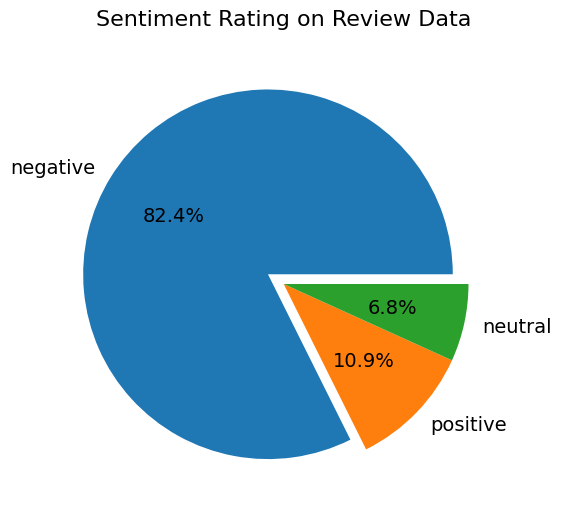

In [21]:
#Membuat objek gambar dan sumbu dengan ukuran (6, 6) inci.
fig, ax = plt.subplots(figsize=(6, 6))

# Mengambil jumlah data polaritas sentimen dari DataFrame 'clean_df' dan menyimpannya dalam list 'sizes'.
sizes = [count for count in clean_df['sentiment_rating'].value_counts()]

# Mengambil label atau kategori sentimen dari DataFrame 'clean_df' dan menyimpannya dalam list 'labels'.
labels = list(clean_df['sentiment_rating'].value_counts().index)

# Menentukan seberapa jauh potongan dari pie chart akan ditarik (0.1 artinya potongan pertama akan sedikit terpisah).
# Ubah explode menjadi panjang yang sama dengan jumlah kategori sentimen (3 dalam kasus ini).
explode = (0.1, 0, 0)

# Membuat pie chart dengan data 'sizes', 'labels', dan 'explode' yang telah ditentukan.
# Autopct digunakan untuk menampilkan persentase di dalam setiap potongan pie.
# Textprops digunakan untuk mengatur ukuran font teks dalam pie chart.
ax.pie(x=sizes, labels=labels, autopct='%1.1f%%', explode=explode, textprops={'fontsize': 14})

# Menetapkan judul untuk pie chart dengan ukuran font dan jarak (padding) tertentu.
ax.set_title('Sentiment Rating on Review Data', fontsize=16, pad=20)

# Menampilkan pie chart.
plt.show()

In [22]:
# Mengatur opsi tampilan Pandas agar kolom dapat menampilkan teks hingga 3000 karakter.
pd.set_option('display.max_colwidth', 3000)

# Membuat DataFrame baru 'positive_tweets' yang hanya berisi tweet dengan polaritas positif.
positive_tweets = clean_df[clean_df['polarity'] == 'positive']

# Memilih hanya kolom-kolom tertentu dari DataFrame 'positive_tweets'.
positive_tweets = positive_tweets[['text_akhir', 'polarity_score', 'polarity','text_stopword']]

# Mengurutkan DataFrame 'positive_tweets' berdasarkan 'polarity_score' secara menurun.
positive_tweets = positive_tweets.sort_values(by='polarity_score', ascending=False)

# Mengatur ulang indeks DataFrame agar dimulai dari 0.
positive_tweets = positive_tweets.reset_index(drop=True)

# Menambahkan 1 ke semua indeks DataFrame.
positive_tweets.index += 1

In [23]:
# Mengatur opsi tampilan Pandas agar kolom dapat menampilkan teks hingga 3000 karakter.
pd.set_option('display.max_colwidth', 3000)

# Membuat DataFrame baru 'negative_tweets' yang hanya berisi tweet dengan polaritas negatif.
negative_tweets = clean_df[clean_df['polarity'] == 'negative']

# Memilih hanya kolom-kolom tertentu dari DataFrame 'negative_tweets'.
negative_tweets = negative_tweets[['text_akhir', 'polarity_score', 'polarity','text_stopword']]

# Mengurutkan DataFrame 'negative_tweets' berdasarkan 'polarity_score' secara menaik (ascending).
negative_tweets = negative_tweets.sort_values(by='polarity_score', ascending=True)

# Memilih 10 baris pertama dari DataFrame yang sudah diurutkan.
negative_tweets = negative_tweets[0:10]

# Mengatur ulang indeks DataFrame agar dimulai dari 0.
negative_tweets = negative_tweets.reset_index(drop=True)

# Menambahkan 1 ke semua indeks DataFrame.
negative_tweets.index += 1

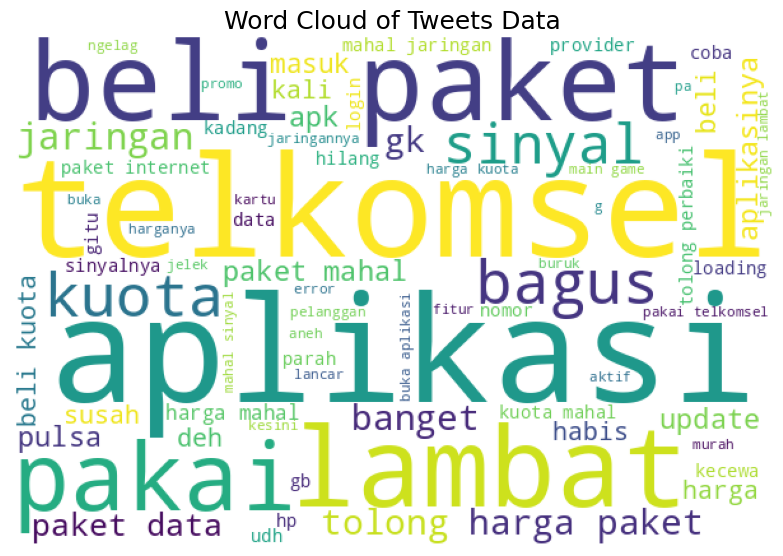

In [24]:
# Membuat string kosong 'list_words' yang akan digunakan untuk mengumpulkan semua kata dari teks yang sudah dibersihkan.
list_words = ''

# Iterasi melalui setiap tweet dalam kolom 'text_stopword' dari DataFrame 'clean_df'.
for tweet in clean_df['text_stopword']:
    # Iterasi melalui setiap kata dalam tweet.
    for word in tweet:
        # Menambahkan kata ke dalam 'list_words'.
        list_words += ' ' + (word)

# Membuat objek WordCloud dengan parameter tertentu.
wordcloud = WordCloud(width=600, height=400, background_color='white', min_font_size=10).generate(list_words)

# Membuat gambar dan sumbu untuk menampilkan word cloud.
fig, ax = plt.subplots(figsize=(8, 6))

# Menetapkan judul untuk word cloud.
ax.set_title('Word Cloud of Tweets Data', fontsize=18)

# Menonaktifkan grid pada sumbu.
ax.grid(False)

# Menampilkan word cloud dalam gambar.
ax.imshow((wordcloud))

# Mengatur layout gambar.
fig.tight_layout(pad=0)

# Menyembunyikan sumbu.
ax.axis('off')

# Menampilkan word cloud.
plt.show()

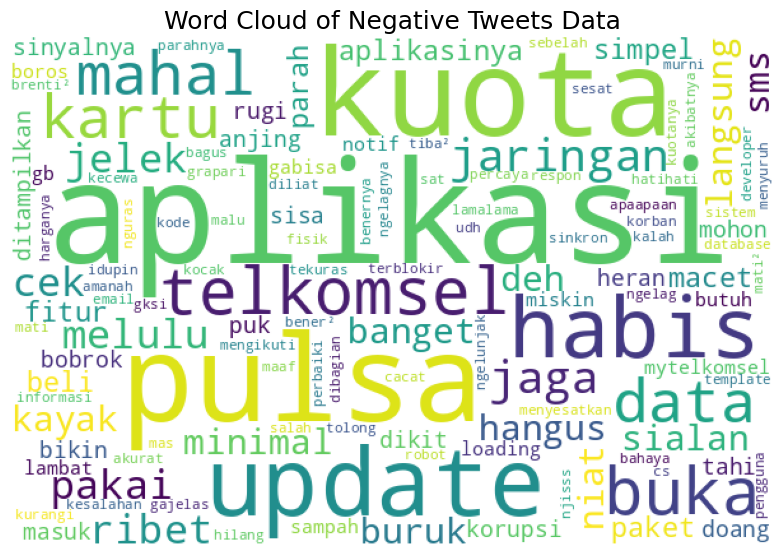

In [25]:
# Membuat string kosong 'list_words' yang akan digunakan untuk mengumpulkan semua kata dari teks yang sudah dibersihkan dalam tweet negatif.
list_words = ''

# Iterasi melalui setiap tweet dalam kolom 'text_stopword' dari DataFrame 'negative_tweets'.
for tweet in negative_tweets['text_stopword']:
    # Iterasi melalui setiap kata dalam tweet.
    for word in tweet:
        # Menambahkan kata ke dalam 'list_words'.
        list_words += ' ' + (word)

# Membuat objek WordCloud dengan parameter tertentu.
wordcloud = WordCloud(width=600, height=400, background_color='white', min_font_size=10).generate(list_words)

# Membuat gambar dan sumbu untuk menampilkan word cloud.
fig, ax = plt.subplots(figsize=(8, 6))

# Menetapkan judul untuk word cloud.
ax.set_title('Word Cloud of Negative Tweets Data', fontsize=18)

# Menonaktifkan grid pada sumbu.
ax.grid(False)

# Menampilkan word cloud dalam gambar.
ax.imshow((wordcloud))

# Mengatur layout gambar.
fig.tight_layout(pad=0)

# Menyembunyikan sumbu.
ax.axis('off')

# Menampilkan word cloud.
plt.show()

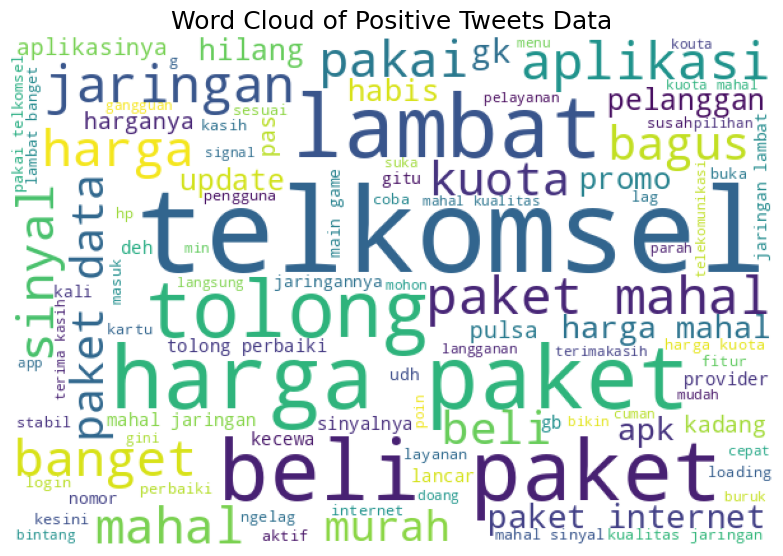

In [26]:
# Membuat string kosong 'list_words' yang akan digunakan untuk mengumpulkan semua kata dari teks yang sudah dibersihkan dalam tweet positif.
list_words = ''

# Iterasi melalui setiap tweet dalam kolom 'text_stopword' dari DataFrame 'positive_tweets'.
for tweet in positive_tweets['text_stopword']:
    # Iterasi melalui setiap kata dalam tweet.
    for word in tweet:
        # Menambahkan kata ke dalam 'list_words'.
        list_words += ' ' + (word)

# Membuat objek WordCloud dengan parameter tertentu.
wordcloud = WordCloud(width=600, height=400, background_color='white', min_font_size=10).generate(list_words)

# Membuat gambar dan sumbu untuk menampilkan word cloud.
fig, ax = plt.subplots(figsize=(8, 6))

# Menetapkan judul untuk word cloud.
ax.set_title('Word Cloud of Positive Tweets Data', fontsize=18)

# Menonaktifkan grid pada sumbu.
ax.grid(False)

# Menampilkan word cloud dalam gambar.
ax.imshow((wordcloud))

# Mengatur layout gambar.
fig.tight_layout(pad=0)

# Menyembunyikan sumbu.
ax.axis('off')

# Menampilkan word cloud.
plt.show()

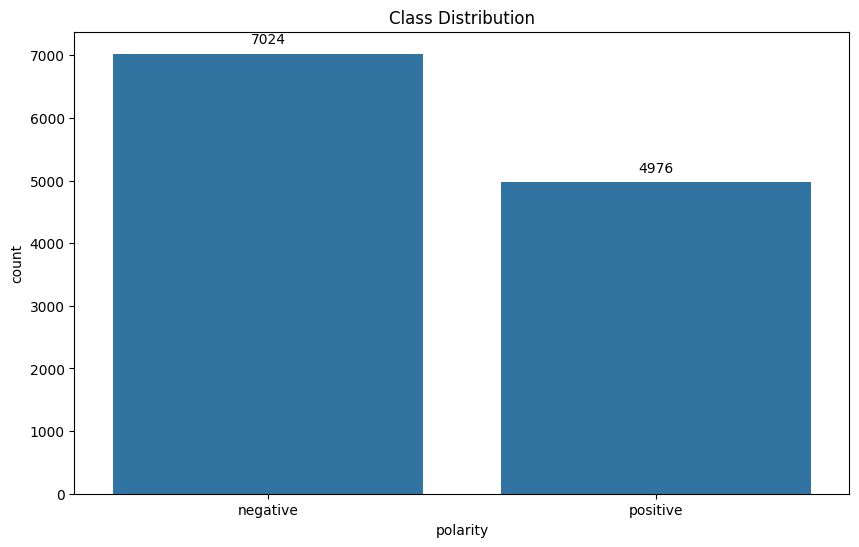

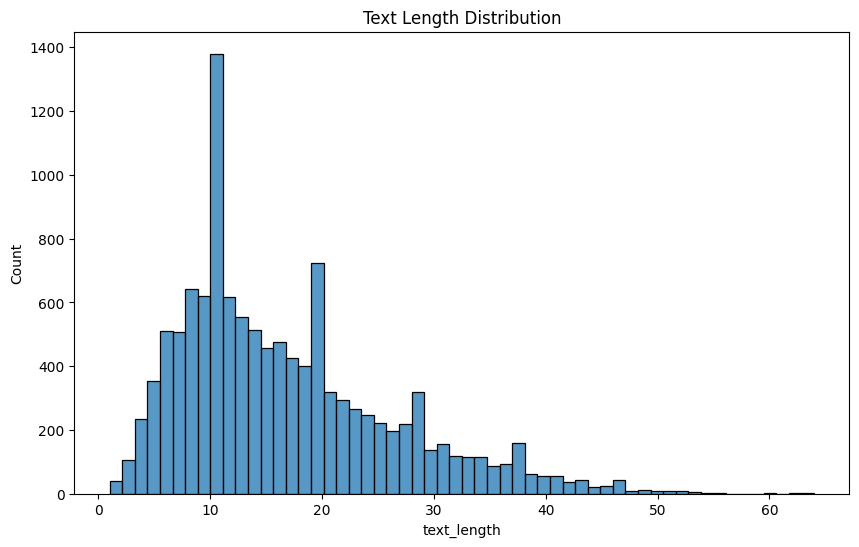

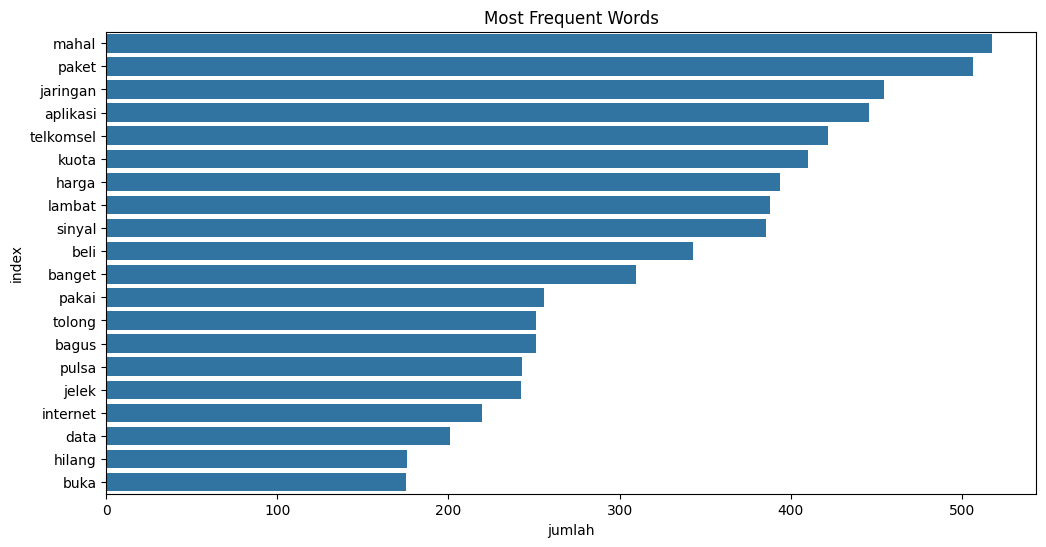

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

# Set the figure size
plt.figure(figsize=(10, 6))

# Check class distribution
class_dist_plot = sns.countplot(x='polarity', data=clean_df)
plt.title('Class Distribution')

# Add counts above the bars on the plot
for p in class_dist_plot.patches:
    class_dist_plot.annotate(format(p.get_height(), '.0f'),
                              (p.get_x() + p.get_width() / 2., p.get_height()),
                              ha='center', va='center',
                              xytext=(0, 10),
                              textcoords='offset points')

plt.show()

# Set the figure size
plt.figure(figsize=(10, 6))

# Visualize text length distribution
clean_df['text_length'] = clean_df['text_akhir'].apply(lambda x: len(x.split()))
sns.histplot(clean_df['text_length'])
plt.title('Text Length Distribution')
plt.show()

# Set the figure size
plt.figure(figsize=(12, 6))

# Visualize most frequent words
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(clean_df['text_akhir'])
tfidf_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
tfidf_df = tfidf_df.sum().reset_index(name='jumlah')
tfidf_df = tfidf_df.sort_values('jumlah', ascending=False).head(20)
sns.barplot(x='jumlah', y='index', data=tfidf_df)
plt.title('Most Frequent Words')
plt.show()

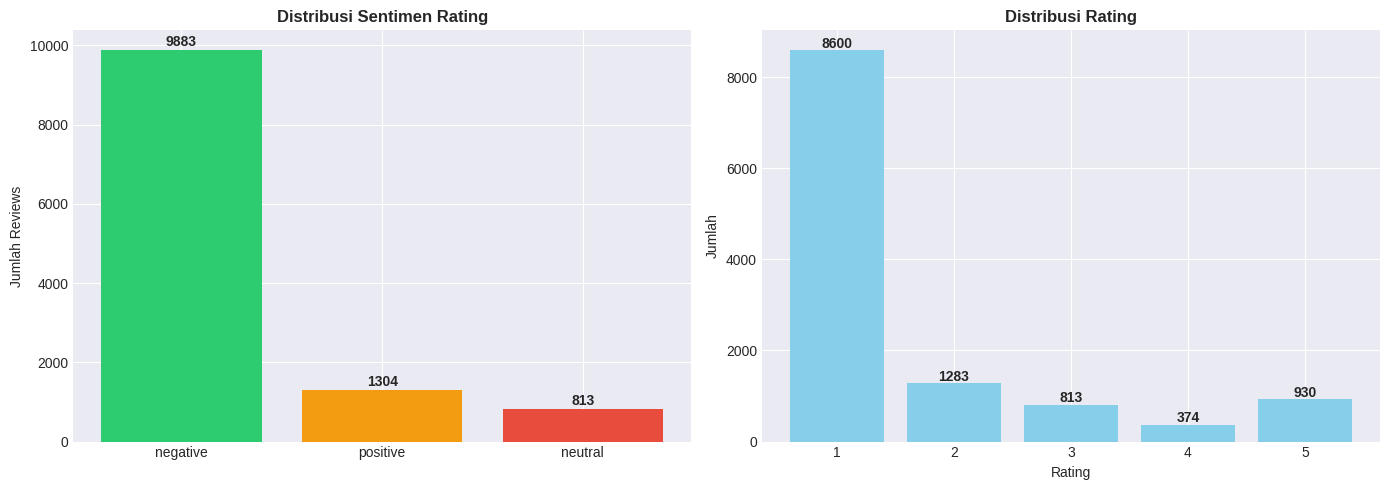

In [28]:
# Setup plot style
plt.style.use('seaborn-v0_8-darkgrid')
fig, axes = plt.subplots(1, 2, figsize=(14, 5)) # Changed to 1 row, 2 columns

# 1. Distribution of sentiments
sentiment_counts = clean_df['sentiment_rating'].value_counts()
colors = ['#2ecc71', '#f39c12', '#e74c3c']  # green, orange, red
axes[0].bar(sentiment_counts.index, sentiment_counts.values, color=colors) # Changed axes[0,0] to axes[0]
axes[0].set_title('Distribusi Sentimen Rating', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Jumlah Reviews')
for i, v in enumerate(sentiment_counts.values):
    axes[0].text(i, v + 100, str(v), ha='center', fontweight='bold')

# 2. Rating distribution
rating_counts = clean_df['score'].value_counts().sort_index()
axes[1].bar(rating_counts.index, rating_counts.values, color='skyblue') # Changed axes[0,1] to axes[1]
axes[1].set_title('Distribusi Rating', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Jumlah')
for i, (idx, v) in enumerate(rating_counts.items()):
    axes[1].text(idx, v + 50, str(v), ha='center', fontweight='bold')

plt.tight_layout() # Add tight_layout to prevent labels from overlapping
plt.show() # Show the plot

## SKEMA 1: SVM + TF-IDF (80/20 split)

In [29]:
print("\n" + "="*70)
print("SKEMA 1: SVM dengan TF-IDF Feature Extraction")
print("="*70 + "\n")

# Encode the sentiment_rating column to numerical values
sentiment_mapping = {'negative': 0, 'positive': 1}
clean_df['sentiment_encoded'] = clean_df['polarity'].map(sentiment_mapping)

# Split data 80/20
X_train_s1, X_test_s1, y_train_s1, y_test_s1 = train_test_split(
    clean_df['text_akhir'], # Changed from 'processed_text' to 'text_akhir'
    clean_df['sentiment_encoded'], # Changed from 'sentiment_encoded' to encoded column
    test_size=0.2,
    random_state=42,
    stratify=clean_df['sentiment_encoded'] # Changed from df['sentiment_encoded'] to clean_df['sentiment_encoded']
)

print(f"Data split (80/20):")
print(f"Training set: {len(X_train_s1)} samples")
print(f"Testing set: {len(X_test_s1)} samples")

# TF-IDF Vectorization
print("\n🔧 Melakukan TF-IDF vectorization...")
tfidf_vectorizer_s1 = TfidfVectorizer(
   max_features=5000,
   ngram_range=(1, 2),
   min_df=2,
   max_df=0.8)
X_train_tfidf_s1 = tfidf_vectorizer_s1.fit_transform(X_train_s1)
X_test_tfidf_s1 = tfidf_vectorizer_s1.transform(X_test_s1)

print(f"TF-IDF shape: {X_train_tfidf_s1.shape}")
print(f"Features created: {X_train_tfidf_s1.shape[1]}")

# Training SVM
print("\nTraining SVM classifier...")
svm_model_s1 = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42, verbose=0)
svm_model_s1.fit(X_train_tfidf_s1, y_train_s1)
print("SVM training selesai")

# Prediction
y_pred_train_s1 = svm_model_s1.predict(X_train_tfidf_s1)
y_pred_test_s1 = svm_model_s1.predict(X_test_tfidf_s1)

# Evaluation
accuracy_train_s1 = accuracy_score(y_train_s1, y_pred_train_s1)
accuracy_test_s1 = accuracy_score(y_test_s1, y_pred_test_s1)
precision_s1 = precision_score(y_test_s1, y_pred_test_s1, average='weighted')
recall_s1 = recall_score(y_test_s1, y_pred_test_s1, average='weighted')
f1_s1 = f1_score(y_test_s1, y_pred_test_s1, average='weighted')

print("\nHASIL EVALUASI SKEMA 1:")
print(f"Training Accuracy: {accuracy_train_s1*100:.2f}%")
print(f"Testing Accuracy:  {accuracy_test_s1*100:.2f}%")
print(f"Precision (weighted): {precision_s1*100:.2f}%")
print(f"Recall (weighted):    {recall_s1*100:.2f}%")
print(f"F1-Score (weighted):  {f1_s1*100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test_s1, y_pred_test_s1,
                          target_names=['Negative', 'Positive']))

# Confusion Matrix
cm_s1 = confusion_matrix(y_test_s1, y_pred_test_s1)
print("\nConfusion Matrix:")
print(cm_s1)

# Store results
scheme_1_results = {
    'name': 'SVM + TF-IDF (80/20)',
    'train_accuracy': accuracy_train_s1,
    'test_accuracy': accuracy_test_s1,
    'precision': precision_s1,
    'recall': recall_s1,
    'f1': f1_s1,
    'confusion_matrix': cm_s1
}


SKEMA 1: SVM dengan TF-IDF Feature Extraction

Data split (80/20):
Training set: 9600 samples
Testing set: 2400 samples

🔧 Melakukan TF-IDF vectorization...
TF-IDF shape: (9600, 5000)
Features created: 5000

Training SVM classifier...
SVM training selesai

HASIL EVALUASI SKEMA 1:
Training Accuracy: 99.50%
Testing Accuracy:  88.25%
Precision (weighted): 88.25%
Recall (weighted):    88.25%
F1-Score (weighted):  88.19%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.88      0.92      0.90      1405
    Positive       0.88      0.83      0.85       995

    accuracy                           0.88      2400
   macro avg       0.88      0.87      0.88      2400
weighted avg       0.88      0.88      0.88      2400


Confusion Matrix:
[[1294  111]
 [ 171  824]]


## SKEMA 2: Logistic Regression + TF-IDF (80/20 split)

In [30]:
print("\n" + "="*70)
print("SKEMA 2: Logistic Regression dengan TF-IDF")
print("="*70 + "\n")

from sklearn.linear_model import LogisticRegression

# Split data 80/20
X_train_s2, X_test_s2, y_train_s2, y_test_s2 = train_test_split(
    clean_df['text_akhir'],
    clean_df['sentiment_encoded'],
    test_size=0.2,
    random_state=42,
    stratify=clean_df['sentiment_encoded']
)

print(f"Data split (80/20):")
print(f"Training set: {len(X_train_s2)} samples")
print(f"Testing set: {len(X_test_s2)} samples")

# TF-IDF Vectorization
print("\n🔧 Melakukan TF-IDF vectorization...")

tfidf_vectorizer_s2 = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True
)

X_train_tfidf_s2 = tfidf_vectorizer_s2.fit_transform(X_train_s2)
X_test_tfidf_s2 = tfidf_vectorizer_s2.transform(X_test_s2)

print(f"TF-IDF shape: {X_train_tfidf_s2.shape}")
print(f"Features created: {X_train_tfidf_s2.shape[1]}")

# Logistic Regression
print("\n🚀 Training Logistic Regression...")

lr_model_s2 = LogisticRegression(
    C=4,
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

lr_model_s2.fit(X_train_tfidf_s2, y_train_s2)

print("Training selesai")

# Prediction
y_pred_train_s2 = lr_model_s2.predict(X_train_tfidf_s2)
y_pred_test_s2 = lr_model_s2.predict(X_test_tfidf_s2)

# Evaluation
accuracy_train_s2 = accuracy_score(y_train_s2, y_pred_train_s2)
accuracy_test_s2 = accuracy_score(y_test_s2, y_pred_test_s2)

precision_s2 = precision_score(
    y_test_s2,
    y_pred_test_s2,
    average='weighted'
)

recall_s2 = recall_score(
    y_test_s2,
    y_pred_test_s2,
    average='weighted'
)

f1_s2 = f1_score(
    y_test_s2,
    y_pred_test_s2,
    average='weighted'
)

print("\nHASIL EVALUASI SKEMA 2:")
print(f"Training Accuracy: {accuracy_train_s2*100:.2f}%")
print(f"Testing Accuracy:  {accuracy_test_s2*100:.2f}%")
print(f"Precision (weighted): {precision_s2*100:.2f}%")
print(f"Recall (weighted):    {recall_s2*100:.2f}%")
print(f"F1-Score (weighted):  {f1_s2*100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test_s2,
    y_pred_test_s2,
    target_names=['Negative', 'Positive']
))

# Confusion Matrix
cm_s2 = confusion_matrix(y_test_s2, y_pred_test_s2)

print("\nConfusion Matrix:")
print(cm_s2)

# Store results
scheme_2_results = {
    'name': 'Logistic Regression + TF-IDF (80/20)',
    'train_accuracy': accuracy_train_s2,
    'test_accuracy': accuracy_test_s2,
    'precision': precision_s2,
    'recall': recall_s2,
    'f1': f1_s2,
    'confusion_matrix': cm_s2
}


SKEMA 2: Logistic Regression dengan TF-IDF

Data split (80/20):
Training set: 9600 samples
Testing set: 2400 samples

🔧 Melakukan TF-IDF vectorization...
TF-IDF shape: (9600, 10000)
Features created: 10000

🚀 Training Logistic Regression...
Training selesai

HASIL EVALUASI SKEMA 2:
Training Accuracy: 98.07%
Testing Accuracy:  88.75%
Precision (weighted): 88.81%
Recall (weighted):    88.75%
F1-Score (weighted):  88.77%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.90      0.90      1405
    Positive       0.86      0.88      0.87       995

    accuracy                           0.89      2400
   macro avg       0.88      0.89      0.88      2400
weighted avg       0.89      0.89      0.89      2400


Confusion Matrix:
[[1258  147]
 [ 123  872]]


## SKEMA 3: Vector Ensemble + TF-IDF (80/20 split)

In [36]:
print("\n" + "="*70)
print("SKEMA 3: Vector Ensemble dengan TF-IDF Feature Extraction")
print("="*70 + "\n")

# Split data 80/20
X_train_s3, X_test_s3, y_train_s3, y_test_s3 = train_test_split(
    clean_df['text_akhir'],
    clean_df['sentiment_encoded'],
    test_size=0.2,
    random_state=42,
    stratify=clean_df['sentiment_encoded']
)

print(f"Data split (80/20):")
print(f"Training set: {len(X_train_s3)} samples")
print(f"Testing set: {len(X_test_s3)} samples")

# TF-IDF Vectorization
print("\nMelakukan TF-IDF vectorization...")
tfidf_vectorizer_s3 = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.7,
    sublinear_tf=True,
    use_idf=True,
    smooth_idf=True,
    strip_accents='unicode'
)
X_train_tfidf_s3 = tfidf_vectorizer_s3.fit_transform(X_train_s3)
X_test_tfidf_s3 = tfidf_vectorizer_s3.transform(X_test_s3)

print(f"TF-IDF shape before selection: {X_train_tfidf_s3.shape}")

# Feature Selection (MUST be before model training)
print("\nMelakukan Feature Selection...")
selector = SelectKBest(chi2, k=1500)
X_train_tfidf_s3 = selector.fit_transform(X_train_tfidf_s3, y_train_s3)
X_test_tfidf_s3 = selector.transform(X_test_tfidf_s3)

print(f"TF-IDF shape after selection: {X_train_tfidf_s3.shape}")
print(f"Features created: {X_train_tfidf_s3.shape[1]}")

# Training Random Forest (MUST be before VotingClassifier)
print("\nTraining Random Forest classifier...")
rf_model_s3 = RandomForestClassifier(
    n_estimators=300,           # Increase from 200
    max_depth=15,               # Reduce from 20 (prevent overfitting)
    min_samples_split=10,       # Increase from 5
    min_samples_leaf=4,         # Add this constraint
    max_features='sqrt',        # Better than default 'auto'
    class_weight='balanced',    # Handle class imbalance
    random_state=42,
    n_jobs=-1
)
rf_model_s3.fit(X_train_tfidf_s3, y_train_s3)
print("Random Forest training selesai")

# Cross-validation for Random Forest
print("\nCross-validation...")
cv_scores = cross_val_score(
    rf_model_s3,
    X_train_tfidf_s3,
    y_train_s3,
    cv=5,
    scoring='f1_weighted'
)
print(f"Cross-validation F1-scores: {cv_scores}")
print(f"Mean CV F1-score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# Training Voting Classifier (ensemble)
print("\nTraining Voting Classifier ensemble...")

# Calibrate LinearSVC to provide predict_proba
calibrated_svc = CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=2000, dual=False), method='sigmoid', cv=3)

voting_clf = VotingClassifier(
    estimators=[
        ('rf', rf_model_s3),
        ('svc', calibrated_svc),
        ('lr', LogisticRegression(random_state=42, max_iter=1000))
    ],
    voting='soft'
)
voting_clf.fit(X_train_tfidf_s3, y_train_s3)
print("Voting Classifier training selesai")

# Prediction using Voting Classifier
y_pred_train_s3 = voting_clf.predict(X_train_tfidf_s3)
y_pred_test_s3 = voting_clf.predict(X_test_tfidf_s3)

# Evaluation
accuracy_train_s3 = accuracy_score(y_train_s3, y_pred_train_s3)
accuracy_test_s3 = accuracy_score(y_test_s3, y_pred_test_s3)
precision_s3 = precision_score(y_test_s3, y_pred_test_s3, average='weighted')
recall_s3 = recall_score(y_test_s3, y_pred_test_s3, average='weighted')
f1_s3 = f1_score(y_test_s3, y_pred_test_s3, average='weighted')

print("\nHASIL EVALUASI SKEMA 3 (Voting Ensemble):")
print(f"Training Accuracy: {accuracy_train_s3*100:.2f}%")
print(f"Testing Accuracy:  {accuracy_test_s3*100:.2f}%")
print(f"Precision (weighted): {precision_s3*100:.2f}%")
print(f"Recall (weighted):    {recall_s3*100:.2f}%")
print(f"F1-Score (weighted):  {f1_s3*100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test_s3, y_pred_test_s3,
                          target_names=['Negative', 'Positive']))

# Confusion Matrix
cm_s3 = confusion_matrix(y_test_s3, y_pred_test_s3)
print("\nConfusion Matrix:")
print(cm_s3)

# Store results
scheme_3_results = {
    'name': 'Voting Ensemble (RF + SVC + LR) + TF-IDF (80/20)',
    'train_accuracy': accuracy_train_s3,
    'test_accuracy': accuracy_test_s3,
    'precision': precision_s3,
    'recall': recall_s3,
    'f1': f1_s3,
    'confusion_matrix': cm_s3
}


SKEMA 3: Vector Ensemble dengan TF-IDF Feature Extraction

Data split (80/20):
Training set: 9600 samples
Testing set: 2400 samples

Melakukan TF-IDF vectorization...
TF-IDF shape before selection: (9600, 3000)

Melakukan Feature Selection...
TF-IDF shape after selection: (9600, 1500)
Features created: 1500

Training Random Forest classifier...
Random Forest training selesai

Cross-validation...
Cross-validation F1-scores: [0.78651646 0.79766091 0.79208677 0.79397928 0.78848492]
Mean CV F1-score: 0.7917 (+/- 0.0040)

Training Voting Classifier ensemble...
Voting Classifier training selesai

HASIL EVALUASI SKEMA 3 (Voting Ensemble):
Training Accuracy: 92.61%
Testing Accuracy:  87.62%
Precision (weighted): 87.59%
Recall (weighted):    87.62%
F1-Score (weighted):  87.60%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.90      0.90      1405
    Positive       0.86      0.84      0.85       995

    accuracy                    

## All Model Result


RINGKASAN PERBANDINGAN SEMUA SKEMA PELATIHAN

📊 Tabel Perbandingan:
                                           Skema Train Accuracy Test Accuracy Precision Recall F1-Score
                            SVM + TF-IDF (80/20)         99.50%        88.25%    88.25% 88.25%   88.19%
            Logistic Regression + TF-IDF (80/20)         98.07%        88.75%    88.81% 88.75%   88.77%
Voting Ensemble (RF + SVC + LR) + TF-IDF (80/20)         92.61%        87.62%    87.59% 87.62%   87.60%


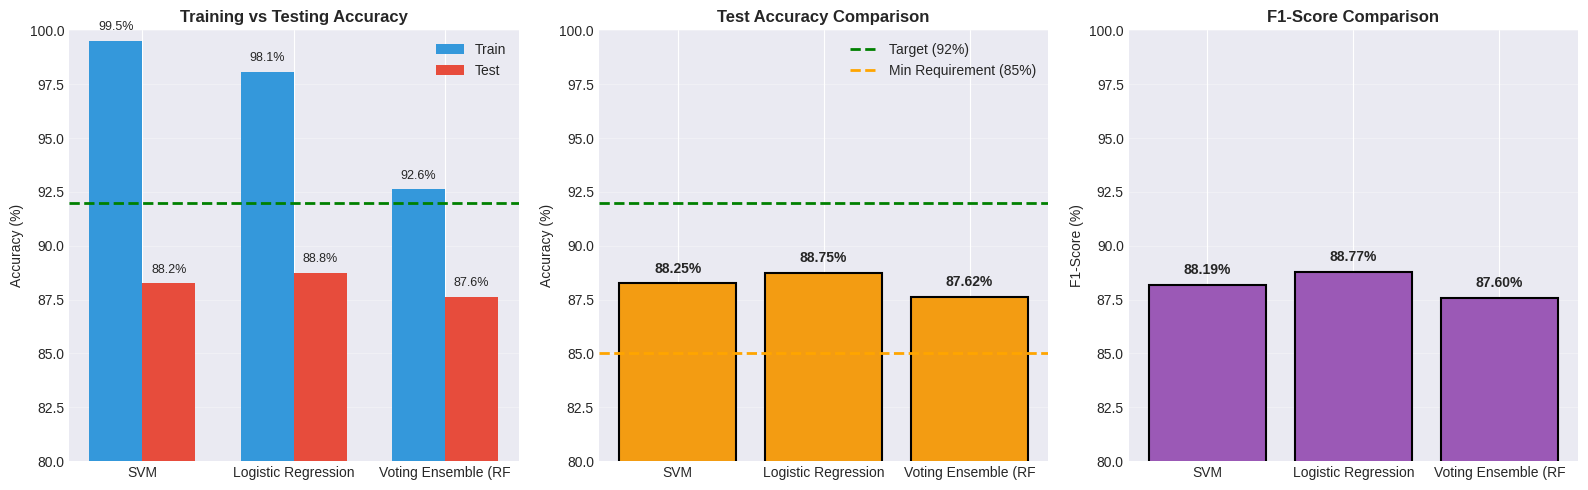


✅ Visualization saved


In [37]:
print("\n" + "="*80)
print("RINGKASAN PERBANDINGAN SEMUA SKEMA PELATIHAN")
print("="*80)

# Compile results
results_list = [scheme_1_results, scheme_2_results, scheme_3_results]

results_df = pd.DataFrame([
    {
        'Skema': r['name'],
        'Train Accuracy': f"{r['train_accuracy']*100:.2f}%",
        'Test Accuracy': f"{r['test_accuracy']*100:.2f}%",
        'Precision': f"{r['precision']*100:.2f}%",
        'Recall': f"{r['recall']*100:.2f}%",
        'F1-Score': f"{r['f1']*100:.2f}%"
    }
    for r in results_list
])

print("\n📊 Tabel Perbandingan:")
print(results_df.to_string(index=False))

# Visualisasi perbandingan
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

scheme_names = [r['name'].split(' +')[0] for r in results_list]
train_accs = [r['train_accuracy']*100 for r in results_list]
test_accs = [r['test_accuracy']*100 for r in results_list]
f1_scores = [r['f1']*100 for r in results_list]

# Train vs Test Accuracy
bar_width = 0.35
x = np.arange(len(scheme_names))
axes[0].bar(x - bar_width/2, train_accs, bar_width, label='Train', color='#3498db')
axes[0].bar(x + bar_width/2, test_accs, bar_width, label='Test', color='#e74c3c')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Training vs Testing Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(scheme_names)
axes[0].legend()
axes[0].set_ylim([80, 100])
axes[0].axhline(y=92, color='green', linestyle='--', linewidth=2, label='Target (92%)')
axes[0].grid(True, alpha=0.3, axis='y')

for i, (train, test) in enumerate(zip(train_accs, test_accs)):
    axes[0].text(i - bar_width/2, train + 0.5, f'{train:.1f}%', ha='center', fontsize=9)
    axes[0].text(i + bar_width/2, test + 0.5, f'{test:.1f}%', ha='center', fontsize=9)

# Test Accuracy only
colors_acc = ['#2ecc71' if acc >= 92 else '#f39c12' for acc in test_accs]
axes[1].bar(scheme_names, test_accs, color=colors_acc, edgecolor='black', linewidth=1.5)
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Test Accuracy Comparison', fontsize=12, fontweight='bold')
axes[1].set_ylim([80, 100])
axes[1].axhline(y=92, color='green', linestyle='--', linewidth=2, label='Target (92%)')
axes[1].axhline(y=85, color='orange', linestyle='--', linewidth=2, label='Min Requirement (85%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

for i, acc in enumerate(test_accs):
    axes[1].text(i, acc + 0.5, f'{acc:.2f}%', ha='center', fontweight='bold')

# F1-Score
axes[2].bar(scheme_names, f1_scores, color='#9b59b6', edgecolor='black', linewidth=1.5)
axes[2].set_ylabel('F1-Score (%)')
axes[2].set_title('F1-Score Comparison', fontsize=12, fontweight='bold')
axes[2].set_ylim([80, 100])
axes[2].grid(True, alpha=0.3, axis='y')

for i, f1 in enumerate(f1_scores):
    axes[2].text(i, f1 + 0.5, f'{f1:.2f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('scheme_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

print("\n✅ Visualization saved")

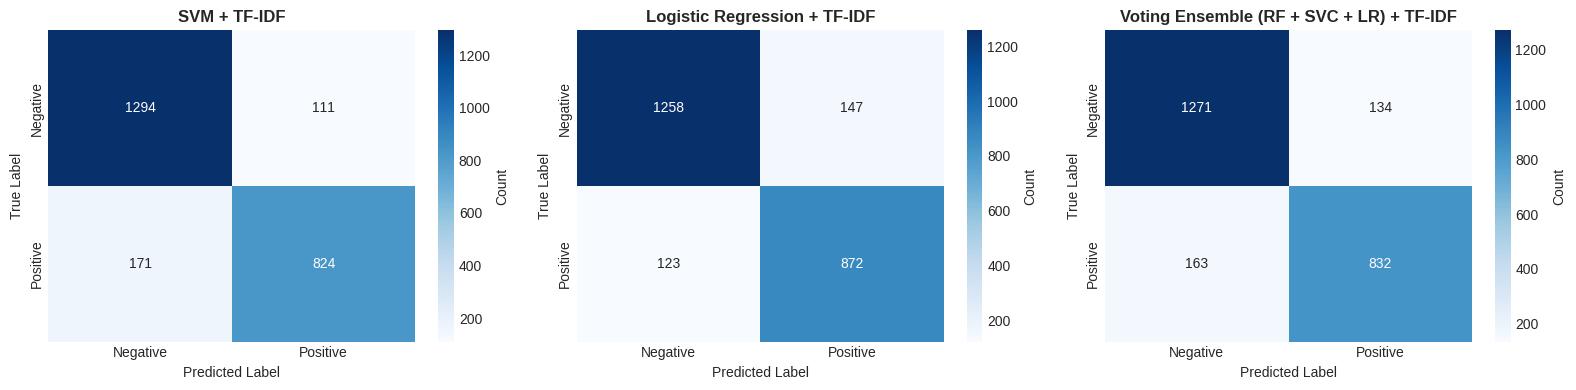

✅ Confusion matrices visualization saved


In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
cm_list = [scheme_1_results['confusion_matrix'],
           scheme_2_results['confusion_matrix'],
           scheme_3_results['confusion_matrix']]
scheme_labels = ['SVM + TF-IDF', 'Logistic Regression + TF-IDF', 'Voting Ensemble (RF + SVC + LR) + TF-IDF']

for idx, (ax, cm, label) in enumerate(zip(axes, cm_list, scheme_labels)):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'],
                cbar_kws={'label': 'Count'})
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.set_ylabel('True Label')
    ax.set_xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=100, bbox_inches='tight')
plt.show()

print("✅ Confusion matrices visualization saved")

## Save Model

In [40]:
print("\n💾 Saving trained models and components...\n")

# Create directory
if not os.path.exists('models'):
    os.makedirs('models')

# Scheme 1
with open('models/tfidf_vectorizer_s1.pkl', 'wb') as f:
    pickle.dump(tfidf_vectorizer_s1, f)
with open('models/svm_model_s1.pkl', 'wb') as f:
    pickle.dump(svm_model_s1, f)
print("✅ Scheme 1 (SVM + TF-IDF) saved")

# Scheme 2
with open('models/tfidf_vectorizer_s2.pkl', 'wb') as f:
    pickle.dump(tfidf_vectorizer_s2, f)
with open('models/lr_model_s2.pkl', 'wb') as f:
    pickle.dump(lr_model_s2, f)
print("✅ Scheme 2 (LR + TF-IDF) saved")

# Scheme 3
with open('models/tfidf_vectorizer_s3.pkl', 'wb') as f:
    pickle.dump(tfidf_vectorizer_s3, f)
with open('models/voting_clf.pkl', 'wb') as f:
    pickle.dump(voting_clf, f)
print("✅ Scheme 3 (Voting Ensemble + TF-IDF) saved")

# Summary
print("\n📁 Saved files:")
print("  - models/tfidf_vectorizer_s1.pkl")
print("  - models/svm_model_s1.pkl")
print("  - models/tfidf_vectorizer_s2.pkl")
print("  - models/rf_model_s2.pkl")
print("  - models/tfidf_vectorizer_s3.pkl")
print("  - models/voting_clf.pkl")


💾 Saving trained models and components...

✅ Scheme 1 (SVM + TF-IDF) saved
✅ Scheme 2 (LR + TF-IDF) saved
✅ Scheme 3 (Voting Ensemble + TF-IDF) saved

📁 Saved files:
  - models/tfidf_vectorizer_s1.pkl
  - models/svm_model_s1.pkl
  - models/tfidf_vectorizer_s2.pkl
  - models/rf_model_s2.pkl
  - models/tfidf_vectorizer_s3.pkl
  - models/voting_clf.pkl


In this Sentiment Analysis case, the SVM + TF-IDF algorithm achieved the highest training accuracy while still maintaining a good test accuracy, close to that of Logistic Regression + TF-IDF. In addition, it produced the highest number of correctly predicted True Negatives (TN). Since the main concern of this sentiment analysis is to prevent negative sentiments, especially criticism and suggestions, from being misclassified as positive, SVM + TF-IDF was chosen as the final model.

## Test Model with New Senteces

In [98]:
# Input kalimat baru dari pengguna
new_sentence = input("Masukkan kalimat baru: ")

# Melakukan preprocessing pada kalimat baru
new_sentence_cleaned = cleaningText(new_sentence)
new_sentence_casefolded = casefoldingText(new_sentence_cleaned)
new_sentence_slangfixed = fix_slangwords(new_sentence_casefolded)
new_sentence_tokenized = tokenizingText(new_sentence_slangfixed)
new_sentence_filtered = filteringText(new_sentence_tokenized)
new_sentence_final = toSentence(new_sentence_filtered)

# Menggunakan objek tfidf yang sudah di-fit dari pelatihan sebelumnya
X_new_sentences = tfidf_vectorizer_s1.transform([new_sentence_final])

# Apply the same feature selection as during training
# The selector is not used for svm_model_s1 from Scheme 1, so this line is commented out.
# X_new_sentences = selector.transform(X_new_sentences_tfidf)

# Memperoleh prediksi sentimen kalimat baru
sentimen_prediction = svm_model_s1.predict(X_new_sentences)

# Menampilkan hasil prediksi
if sentimen_prediction[0] == 1:
    print("Sentimen kalimat baru adalah POSITIF.")
else:
    print("Sentimen kalimat baru adalah NEGATIF.")

Masukkan kalimat baru: Pegel banget sinyal lemot & jelek
Sentimen kalimat baru adalah NEGATIF.


In [107]:
# Contoh ulasan positif dan negatif untuk pengujian
sample_reviews = [
    "Beli paket telkomsel tergolong murah dibandingkan dengan brand lain & kualitasnya telkomsel tidak diragukan lagi",
    "Aplikasi sering lag, kuota data tidak muncul sesuai"
]

print("--- Hasil Inference Sentimen Kategorikal --- \n")
for new_sentence in sample_reviews:
    new_sentence_cleaned = cleaningText(new_sentence)
    new_sentence_casefolded = casefoldingText(new_sentence_cleaned)
    new_sentence_slangfixed = fix_slangwords(new_sentence_casefolded)
    new_sentence_tokenized = tokenizingText(new_sentence_slangfixed)
    new_sentence_filtered = filteringText(new_sentence_tokenized)
    new_sentence_final = toSentence(new_sentence_filtered)
    X_new_sentences = tfidf_vectorizer_s1.transform([new_sentence_final])
    sentimen_prediction = svm_model_s1.predict(X_new_sentences)
    if sentimen_prediction[0] == 1:
      print(f"Kalimat: {new_sentence}")
      print("Sentimen kalimat baru adalah POSITIF.")
    else:
      print(f"Kalimat: {new_sentence}")
      print("Sentimen kalimat baru adalah NEGATIF.")

--- Hasil Inference Sentimen Kategorikal --- 

Kalimat: Beli paket telkomsel tergolong murah dibandingkan dengan brand lain & kualitasnya telkomsel tidak diragukan lagi
Sentimen kalimat baru adalah POSITIF.
Kalimat: Aplikasi sering lag, kuota data tidak muncul sesuai
Sentimen kalimat baru adalah NEGATIF.
